In [1]:
import os
import tempfile
from ansys.aedt.core import *
import matplotlib.pyplot as plt
import numpy as np
from Auxiliary_CP_Planar import Z_par_g, synth_ant, synth_ant_pos
import pandas as pd
from datetime import datetime
from scipy.optimize import minimize, differential_evolution
from scipy.odr import ODR, Model, RealData
import matplotlib.image as mpimg
import time

start = time.time()
AEDT_VERSION = "2025.2"
NUM_CORES = 4
NG_MODE = False
ConvP = 2
diff_ev_on = False  # Differential evolution optimization on/off

temp_folder = tempfile.TemporaryDirectory(suffix=".ansys")

project_name = os.path.join(temp_folder.name, "Planar_Array.aedt")
design_name = "Planar"
hfss = Hfss(version=AEDT_VERSION,
            non_graphical=NG_MODE,
            project=project_name,
            design=design_name,
            new_desktop=True,
            solution_type="Modal",
            # student_version=True
            )


PyAEDT INFO: Python version 3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0].
PyAEDT INFO: PyAEDT version 0.25.1.
PyAEDT INFO: Initializing new Desktop session.
PyAEDT INFO: AEDT version 2025.2.
PyAEDT INFO: New AEDT session is starting on gRPC port 54091.
PyAEDT INFO: Starting new AEDT gRPC session on port 54091.
PyAEDT INFO: Launching AEDT server with gRPC transport mode: TransportMode.UDS
PyAEDT INFO: Electronics Desktop started on gRPC port 54091 after 46.3 seconds.
PyAEDT INFO: AEDT installation Path /usr/ansys_inc/v252/AnsysEM
PyAEDT INFO: Connected to AEDT gRPC session on port 54091.
PyAEDT WARNING: Service Pack is not detected. PyAEDT is currently connecting in Insecure Mode.
PyAEDT WARNING: Please download and install latest Service Pack to use connect to AEDT in Secure Mode.
PyAEDT INFO: Project Planar_Array has been created.
PyAEDT INFO: Added design 'Planar' of type HFSS.
PyAEDT INFO: AEDT objects correctly read


In [2]:
# User parameters
material = "Arlon AD255A (tm)" # er = 2.55
# material = "Rogers TMM 4 (tm)" # er = 4.5
# material = "Rogers TMM 10i (tm)"  # er = 9.8
# h = 0.003175
h = 0.001524

er = float(hfss.materials[material].permittivity.value)

# Element placement in the array: displacement in x, displacement in y and
# rotation about z for each patch (this replaces Alphas/Betas/Gammas, which
# placed elements on the sphere's surface via a spherical coordinate system)
Xs = np.array([0])
Ys = np.array([0])
Gammas = np.array([0])

center_freq = 1575.42e6
# center_freq = 1575.42e6
band = np.round(((center_freq*er/50*h/0.001524)/1e6+60)/1e3, 2)*1e9
print(band)


PyAEDT INFO: Materials class has been initialized! Elapsed time: 0m 0sec
140000000.0


In [3]:
hfss["numseg"] = "19"  # kept for reference; not used by rectangular geometry
hfss["h"] = str(1000*h)+"mm"

hfss["La1"] = "30mm"
hfss["Wa1"] = "30mm"
hfss["x0_1"] = "10mm"
hfss["y0_1"] = "5mm"

hfss["Rteflon"] = "2.05mm"
Rteflon = 0.00205
hfss["rprobe"] = "0.65mm"
rprobe = 0.00065
hfss["Hprobe"] = "15mm"
Hprobe = 0.015
orange = [255, 128, 64]
red = [255, 0, 0]
blue = [0, 255, 255]
gray = [207, 207, 207]

npoints = 31

geom = [er, h]  # no sphere radius here: only the substrate properties are fixed;
                # La, Wa (patch size) are the design outputs, same role as
                # Dthetaa, Dphia in the spherical code
folder_name = "Results/case_er=" + str(er) + "_h=" + str(h*1000) + "mm_f=" + str(int(center_freq/1e6)) + "MHz"
cur_folder = os.getcwd()
results_folder = os.path.join(cur_folder, folder_name)
os.makedirs(results_folder, exist_ok=True)

# Finite ground/substrate size: patch size (nominal, updated below) plus a margin
Lg = 0.08
Wg = 0.08
Rg = 0.05
hfss["Lg"] = str(1000*Lg)+"mm"
hfss["Wg"] = str(1000*Wg)+"mm"
hfss["Rg"] = str(1000*Rg)+"mm"


In [4]:
# Geometry construction: finite ground plane, finite substrate slab and the
# rectangular patch(es). The spherical version built these by revolving
# polylines (sphere shells); here it is just finite boxes and a rectangle.
hfss.modeler.set_working_coordinate_system("Global")

material_tef = "Teflon (tm)"

Gnd_Name = "Gnd_Plane"
# Gnd = hfss.modeler.create_rectangle(
#     orientation=2,
#     origin=["-Lg/2", "-Wg/2", "0mm"],
#     sizes=["Lg", "Wg"],
#     name=Gnd_Name,
# )
Gnd = hfss.modeler.create_circle(
    orientation="XY",
    origin=["0mm", "0mm", "0mm"],
    radius="Rg",
    name=Gnd_Name,
)
hfss.assign_finite_conductivity(Gnd_Name)
Gnd.color = orange

Diel_Name = "Dielectric"
# Diel = hfss.modeler.create_box(
#     origin=["-Lg/2", "-Wg/2", "0mm"],
#     sizes=["Lg", "Wg", "h"],
#     name=Diel_Name,
#     material=material
# )
Diel = hfss.modeler.create_cylinder(
    orientation="Z",
    origin=["0mm", "0mm", "0mm"],
    radius="Rg",
    height="h",
    name=Diel_Name,
    material=material
)
Diel.color = gray

for i in range(1, len(Xs)+1):
    Patch_Name = "Patch"+str(i)

    if i > 1:
        hfss["La"+str(i)] = hfss["La1"]
        hfss["Wa"+str(i)] = hfss["Wa1"]
        hfss["x0_"+str(i)] = hfss["x0_1"]
        hfss["y0_"+str(i)] = hfss["y0_1"]

    hfss["X"+str(i)] = str(Xs[i-1])+"mm"
    hfss["Y"+str(i)] = str(Ys[i-1])+"mm"
    hfss["Gamma"+str(i)] = str(Gammas[i-1])+"deg"

    Patch = hfss.modeler.create_rectangle(
        orientation=2,
        origin=["-La"+str(i)+"/2", "-Wa"+str(i)+"/2", "h"],
        sizes=["La"+str(i), "Wa"+str(i)],
        name=Patch_Name,
        material="copper"
    )
    hfss.assign_finite_conductivity(Patch_Name)
    Patch.color = orange

    # Coaxial probe at (x0, y0), relative to the CENTER of the patch, before
    # the whole element is displaced/rotated into its array position
    Probe_Name = "Probe"+str(i)
    Probe = hfss.modeler.create_cylinder(
        orientation="Z", origin=["x0_"+str(i), "y0_"+str(i), "h"],
        radius="rprobe", height="-Hprobe-h", name=Probe_Name, material="copper"
    )

    Teflon_Name = "Teflon"+str(i)
    Teflon = hfss.modeler.create_cylinder(
        orientation="Z", origin=["x0_"+str(i), "y0_"+str(i), "0mm"],
        radius="Rteflon", height="-Hprobe", name=Teflon_Name, material=material_tef
    )
    hfss.assign_perfecte_to_sheets(Teflon.faces[2].id, name="PerfE_Teflon"+str(i))

    Pec_Name = "Pec"+str(i)
    Pec = hfss.modeler.create_cylinder(
        orientation="Z", origin=["x0_"+str(i), "y0_"+str(i), "-Hprobe"],
        radius="Rteflon", height="-3mm", name=Pec_Name, material="pec"
    )

    hfss.modeler.subtract(Teflon_Name, Probe_Name, keep_originals=True)
    hfss.wave_port(assignment=hfss.modeler[Teflon_Name].faces[0], name="Wave_Port"+str(i),
                    deembed="Hprobe")

    hfss.modeler.subtract(Gnd_Name, [Probe_Name, Teflon_Name], keep_originals=True)
    # hfss.modeler.subtract(Gnd_Name, Teflon_Name, keep_originals=True)
    hfss.modeler.subtract(Diel_Name, Probe_Name, keep_originals=True)

    # --- Array placement: DISPLACEMENT in x, y and ROTATION about z ---
    # (replaces the Alpha/Beta spherical-coordinate-system placement)
    elem_objs = [Patch_Name, Probe_Name, Teflon_Name, Pec_Name]
    hfss.modeler.rotate(elem_objs, "Z", angle="Gamma"+str(i))
    hfss.modeler.move(elem_objs, ["X"+str(i), "Y"+str(i), "0mm"])

for obj in hfss.modeler.object_names:
    hfss.modeler[obj].transparency = 0

hfss.materials[material_tef].permittivity.value = "1.9"
hfss.materials[material_tef].update()

hfss.modeler.fit_all()


PyAEDT INFO: Modeler class has been initialized! Elapsed time: 0m 0sec
PyAEDT INFO: Boundary Finite Conductivity Coating_Gnd_Plane has been created.
PyAEDT INFO: Boundary Finite Conductivity Coating_Patch1 has been created.
PyAEDT INFO: Boundary Perfect E PerfE_Teflon1 has been created.
PyAEDT INFO: Boundary Wave Port Wave_Port1 has been created.


In [5]:
freq_range = [center_freq-band/2, center_freq+band/2]

open_box = hfss.create_open_region(frequency=str(center_freq/1e9)+"GHz", boundary="PML")

setup = hfss.create_setup(name="Resonance_Band", Frequency=str(center_freq/1e9)+"GHz",
                           MaximumPasses=20, MinimumPasses=2, MinimumConvergedPasses=ConvP,
                           PercentRefinement=30)

int_sweep = setup.add_sweep(name="GPS_Interpolate", sweep_type="Interpolate",
                             RangeStart=str(freq_range[0]/1e9)+"GHz", RangeEnd=str(freq_range[1]/1e9)+"GHz",
                             RangeCount=npoints, SaveFields=True)

hfss.post.update_report_dynamically = True


PyAEDT INFO: Open Region correctly created.
PyAEDT INFO: Project Planar_Array Saved correctly
PyAEDT INFO: Parsing /tmp/tmp_1k443ou.ansys/Planar_Array.aedt.
PyAEDT INFO: File /tmp/tmp_1k443ou.ansys/Planar_Array.aedt correctly loaded. Elapsed time: 0m 0sec
PyAEDT INFO: aedt file load time 0.1583251953125
PyAEDT INFO: PostProcessor class has been initialized! Elapsed time: 0m 0sec
PyAEDT INFO: PostProcessor class has been initialized! Elapsed time: 0m 0sec
PyAEDT INFO: Post class has been initialized! Elapsed time: 0m 0sec


param (mm):  [59.7134144  58.8686504   9.45155176  7.56514095]
estim:  [2.91309790e-03 1.00000000e+00 1.40568179e-02 1.36547701e-02
 1.89895513e-04 1.89895513e-04]
PyAEDT INFO: Project Planar_Array Saved correctly
PyAEDT INFO: Key Desktop/ActiveDSOConfigurations/HFSS correctly changed.
PyAEDT INFO: Solving design setup Resonance_Band
PyAEDT INFO: Design setup Resonance_Band solved correctly in 0.0h 3.0m 45.0s
PyAEDT INFO: Key Desktop/ActiveDSOConfigurations/HFSS correctly changed.
PyAEDT WARNING: No report category provided. Automatically identified Modal Solution Data
PyAEDT INFO: Solution Data Correctly Loaded.
Time to initialize solution data:0.0020112991333007812
Time to initialize solution data:0.0051000118255615234
1542753333.3333333 1575420000.0
pos (mm):  [58.47524413 57.64799649  9.45154603  7.56514536]
estim_pos:  [2.91309790e-03 1.00000000e+00 1.40568179e-02 1.36547701e-02
 8.08980647e-04 8.00222467e-04]
PyAEDT INFO: Project Planar_Array Saved correctly
PyAEDT INFO: Key Desk

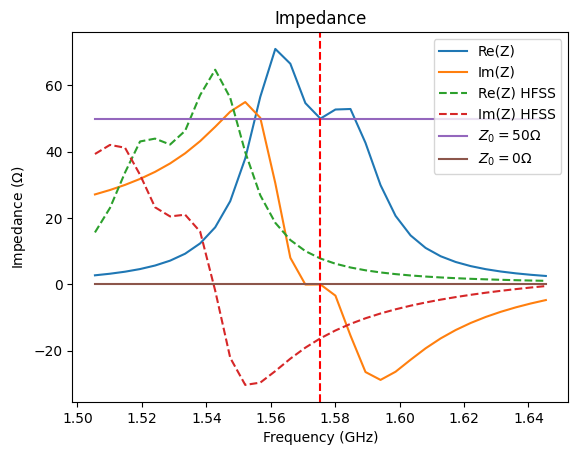

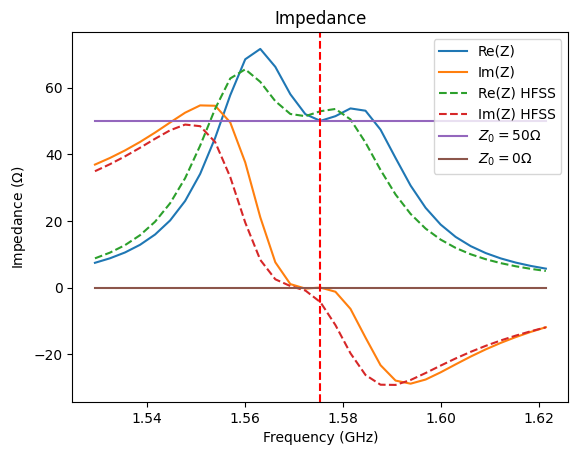

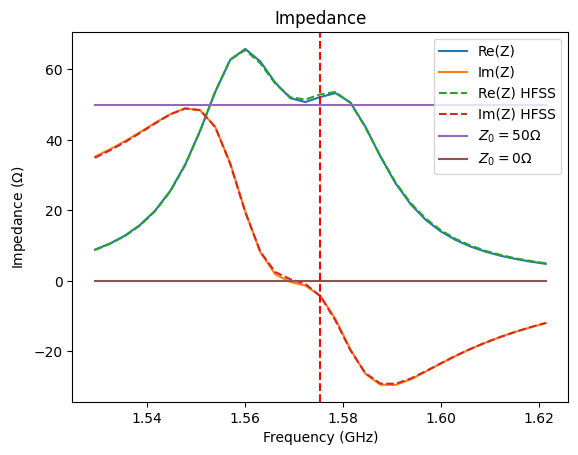

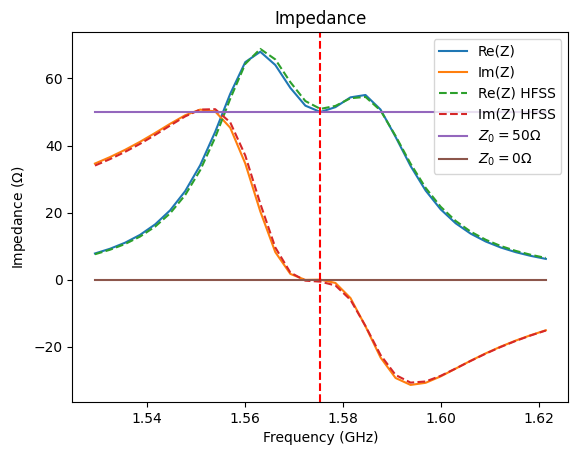

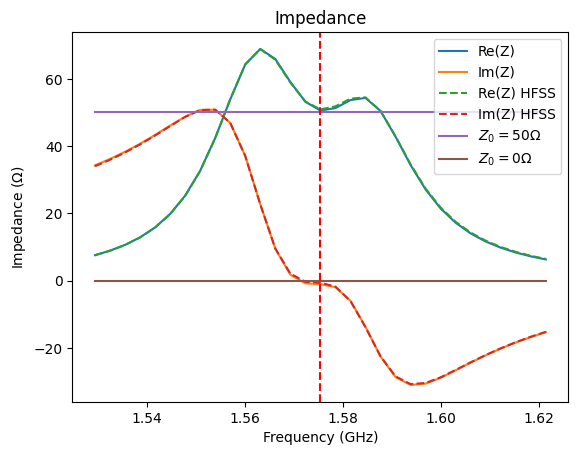

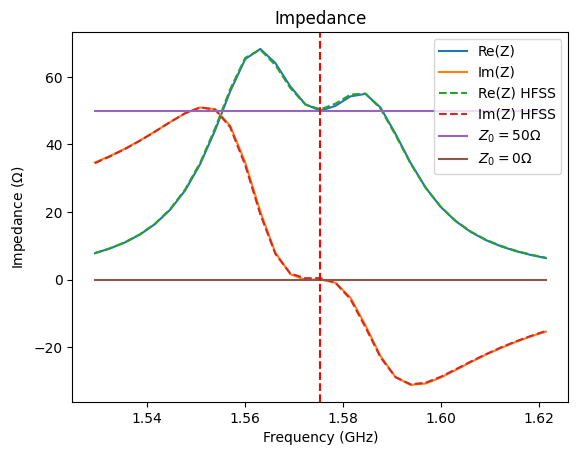

In [6]:
sweep = [freq_range[0], freq_range[1], npoints]
freqs = np.linspace(freq_range[0], freq_range[1], npoints)
Z0 = 50
iT = 0

with open(results_folder+"/history.txt", "a", encoding="utf-8") as f:
    f.write(f"{datetime.now().strftime('%d/%m/%Y %H:%M:%S')}\n")
    f.write("Geometry: [er, h] = " + str(geom) + "\n")
    f.write("Param: La, Wa, x0, y0\n")
    f.write("Estim: dprobe, Y, tg01, tg10, deltaL, deltaW\n\n")

    param, estim = synth_ant(center_freq, geom)
    print('param (mm): ', param*1000)
    print('estim: ', estim)
    f.write(f"Iteration {iT}:\n")
    f.write(f"-> Parameters (m): {param}\n")
    f.write(f"-> Estimates: {estim}\n\n")

    hfss["La1"] = str(round(param[0]*1000, 4)) + "mm"
    hfss["Wa1"] = str(round(param[1]*1000, 4)) + "mm"
    hfss["x0_1"] = str(round(param[2]*1000, 4)) + "mm"
    hfss["y0_1"] = str(round(param[3]*1000, 4)) + "mm"

    setup.analyze()
    reportZ = hfss.post.create_report(expressions=["re(ActiveZ(Wave_Port1:1))", "im(ActiveZ(Wave_Port1:1))"],
                                       setup_sweep_name="GPS_Interpolate", plot_name="Z_11_HFSS_original",
                                       variations=hfss.get_nominal_variation())
    hfss.post.export_report_to_csv(project_dir=results_folder, plot_name="Z_11_HFSS_original")
    Z_int = reportZ.get_solution_data()
    real_z = np.array(Z_int.data_real("re(ActiveZ(Wave_Port1:1))"))
    imag_z = np.array(Z_int.data_real("im(ActiveZ(Wave_Port1:1))"))

    estimIt = estim

    ## begin changes
    print(freqs[np.argmax(real_z)], center_freq)

    def Z_theory(estimIt):
        dprobe, Y, tg01, tg10, deltaL, deltaW = estimIt
        return Z_par_g(dprobe, Y, tg01, tg10, deltaL, deltaW, param[0], param[1], param[2], param[3], sweep, geom)

    ZinP = Z_theory(estimIt)
    plt.figure()
    plt.plot(freqs / 1e9, np.real(ZinP), label='Re(Z)')
    plt.plot(freqs / 1e9, np.imag(ZinP), label='Im(Z)')
    plt.plot(freqs / 1e9, real_z, label='Re(Z) HFSS', linestyle='--')
    plt.plot(freqs / 1e9, imag_z, label='Im(Z) HFSS', linestyle='--')
    plt.plot(freqs / 1e9, [Z0] * len(freqs), label=r'$Z_0=50\Omega$')
    plt.plot(freqs / 1e9, [0] * len(freqs), label=r'$Z_0=0\Omega$')
    plt.axvline(x=center_freq / 1e9, color='r', linestyle='--')
    plt.xlabel('Frequency (GHz)')
    plt.ylabel('Impedance (' + r'$\Omega$' + ')')
    plt.title('Impedance')
    plt.legend()
    plt.savefig(results_folder+'/impedance_comparison'+str(iT)+'.png', format='png', dpi=300)

    # deltaL, deltaW correction from the observed resonance shift (same idea
    # as the deltatheta/deltaPhi correction in the spherical notebook)
    estimIt[4] -= param[0]*(freqs[np.argmax(real_z)]/center_freq-1)/2
    estimIt[5] -= param[1]*(freqs[np.argmax(real_z)]/center_freq-1)/2

    BW = 2*center_freq*np.max([estimIt[2], estimIt[3]])/np.sqrt(2)
    band = 2e6*(np.round(BW/1e6, 0)+15)
    freq_range = [center_freq-band/2, center_freq+band/2]
    sweep = [freq_range[0], freq_range[1], npoints]
    freqs = np.linspace(freq_range[0], freq_range[1], npoints)
    int_sweep.props['RangeStart'] = str(freq_range[0]/1e9)+"GHz"
    int_sweep.props['RangeEnd'] = str(freq_range[1]/1e9)+"GHz"
    int_sweep.update()

    param = synth_ant_pos(center_freq, estimIt, geom)
    print('pos (mm): ', param*1000)
    print('estim_pos: ', estimIt)
    f.write(f"Iteration {iT}:\n")
    f.write(f"-> Parameters (m): {param}\n")
    f.write(f"-> Estimates: {estimIt}\n\n")

    hfss["La1"] = str(round(param[0]*1000, 4)) + "mm"
    hfss["Wa1"] = str(round(param[1]*1000, 4)) + "mm"
    hfss["x0_1"] = str(round(param[2]*1000, 4)) + "mm"
    hfss["y0_1"] = str(round(param[3]*1000, 4)) + "mm"

    # Boresight of a planar patch is along +Z (Theta = 0), not Theta = 90 /
    # Phi = 90 as in the spherical model (there the patch sat at the sphere's
    # equator, so its boresight pointed along +Y = (Theta=90, Phi=90))
    exp_cache = setup.enable_expression_cache(report_type="Far Fields", expressions="dB(AxialRatioValue)",
                                               intrinsics="Theta=\'0deg\' Phi=\'0deg\'",
                                               isrelativeconvergence=False, conv_criteria='0.2')
    converge = hfss.post.available_report_quantities(report_category="Terminal Solution Data",
                                                       quantities_category="Expression Converge")
    hfss.post.create_report([converge[0], converge[1]], setup_sweep_name="Resonance_Band : AdaptivePass",
                             variations=hfss.get_nominal_variation(), primary_sweep_variable="Pass",
                             report_category="Terminal Solution Data", plot_type="Rectangular Plot",
                             plot_name="Convergence")

    setup.analyze()
    ## end changes

    # Bounds for (dprobe, Y, tg01, tg10, deltaL, deltaW)
    bounds = [(1e-4, 0.05), (1e-3, 2), (1e-3, 0.1), (1e-3, 0.1),
              (1e-5, estim[4]+1e-3), (1e-5, estim[5]+1e-3)]

    while 1:
        iT += 1

        def Z_theory(estimIt):
            dprobe, Y, tg01, tg10, deltaL, deltaW = estimIt
            return Z_par_g(dprobe, Y, tg01, tg10, deltaL, deltaW, param[0], param[1], param[2], param[3], sweep, geom)

        Z_int = reportZ.get_solution_data()
        real_z = np.array(Z_int.data_real("re(ActiveZ(Wave_Port1:1))"))
        imag_z = np.array(Z_int.data_real("im(ActiveZ(Wave_Port1:1))"))
        ZinP = Z_theory(estimIt)

        plt.figure()
        plt.plot(freqs / 1e9, np.real(ZinP), label='Re(Z)')
        plt.plot(freqs / 1e9, np.imag(ZinP), label='Im(Z)')
        plt.plot(freqs / 1e9, real_z, label='Re(Z) HFSS', linestyle='--')
        plt.plot(freqs / 1e9, imag_z, label='Im(Z) HFSS', linestyle='--')
        plt.plot(freqs / 1e9, [Z0] * len(freqs), label=r'$Z_0=50\Omega$')
        plt.plot(freqs / 1e9, [0] * len(freqs), label=r'$Z_0=0\Omega$')
        plt.axvline(x=center_freq / 1e9, color='r', linestyle='--')
        plt.xlabel('Frequency (GHz)')
        plt.ylabel('Impedance (' + r'$\Omega$' + ')')
        plt.title('Impedance')
        plt.legend()
        plt.savefig(results_folder+'/impedance_comparison'+str(iT)+'.png', format='png', dpi=300)

        Zhfss = real_z+1j*imag_z
        s11 = 20*np.log10(np.abs((Zhfss-Z0)/(Zhfss+Z0)))

        variations = hfss.get_nominal_variation()
        variations["Theta"] = ["0deg"]
        variations["Phi"] = ["0deg"]
        axialratio_ffd_plot = hfss.post.create_report(expressions="dB(AxialRatioValue)",
                                                       setup_sweep_name="Resonance_Band : LastAdaptive",
                                                       variations=variations,
                                                       primary_sweep_variable="Freq",
                                                       context="3D",
                                                       report_category="Far Fields",
                                                       plot_type="Rectangular Plot",
                                                       plot_name="Center Axial Ratio "+str(iT)+" (dB)"
                                                       )

        AR_value = axialratio_ffd_plot.get_solution_data()
        AR_center = np.array(AR_value.data_real("dB(AxialRatioValue)"))[0]

        print('S11: ', s11, "\n", s11[int((npoints-1)/2)], np.argmin(s11))
        print(AR_center, AR_center < 0.5)
        f.write(f"\nCenter S11: {s11[int((npoints-1)/2)]} dB at {center_freq/1e9} GHz\n")
        f.write(f"S11 min: {np.min(s11)} dB at {freqs[np.argmin(s11)]/1e9} GHz\n")
        f.write(f"Center AR: {AR_center} dB at {center_freq/1e9} GHz\n\n")
        if iT > 2 and s11[int((npoints-1)/2)] < -40 and AR_center < 0.5:
            break
        if iT > 6:
            break

        def cost(estimCost):
            estimCost = np.round(estimCost, 8)
            for i, (low, high) in enumerate(bounds):
                if not (low <= estimCost[i] <= high):
                    return 1e6
            Zt = Z_theory(estimCost)
            cosRes = np.sqrt(np.sum(((np.real(Zt) - real_z)/(real_z+1e-3)) ** 2 +
                                     ((np.imag(Zt) - imag_z)/(imag_z+1e-3)) ** 2)) / npoints
            return np.round(cosRes, 6)

        if iT == 1:
            estimIt[2] *= 1.2   # tg01
            estimIt[3] *= 1.2   # tg10
            estimIt[0] *= 1.1   # dprobe
            estimIt[1] = 1.1    # Y
            f.write(f"-> Estimates between: {estimIt}\n\n")

        if diff_ev_on:
            np.random.seed(0)
            res_global = differential_evolution(cost, bounds, maxiter=70)
            estimIt = res_global.x

        for _ in range(3):
            print('nelder-mead')
            print(estimIt)
            result = minimize(cost, estimIt, method='nelder-mead', tol=1e-10)
            print()
            estimIt = result.x

        print('estimIt_pos_nelder: ', estimIt)

        def Z_theory_odr(beta, x):
            for val, (low, high) in zip(beta, bounds):
                if not (low <= val <= high):
                    return np.full(x.shape[1], 1e10)
            f, i = x
            v = Z_par_g(*beta, param[0], param[1], param[2], param[3], [f, f, 1], geom)
            return np.real(v) * i + np.imag(v) * (1 - i)

        x_full = np.concatenate([freqs, freqs])
        i_full = np.concatenate([np.ones_like(freqs), np.zeros_like(freqs)])
        X = np.vstack([x_full, i_full])
        y_full = np.concatenate([real_z, imag_z])
        sx = np.full_like(X, 0.01)
        sy = np.full_like(y_full, 0.01)

        odr = ODR(RealData(X, y_full, sx=sx, sy=sy), Model(Z_theory_odr), beta0=estimIt)
        estimIt = odr.run().beta

        print("\nAdjusted ODR Estimates:", estimIt, '\n')

        ZinP = [Z_par_g(*estimIt, param[0], param[1], param[2], param[3], [f, f, 1], geom)[0] for f in freqs]

        plt.figure()
        plt.plot(freqs / 1e9, np.real(ZinP), label='Re(Z)')
        plt.plot(freqs / 1e9, np.imag(ZinP), label='Im(Z)')
        plt.plot(freqs / 1e9, real_z, label='Re(Z) HFSS', linestyle='--')
        plt.plot(freqs / 1e9, imag_z, label='Im(Z) HFSS', linestyle='--')
        plt.plot(freqs / 1e9, [Z0] * len(freqs), label=r'$Z_0=50\Omega$')
        plt.plot(freqs / 1e9, [0] * len(freqs), label=r'$Z_0=0\Omega$')
        plt.axvline(x=center_freq / 1e9, color='r', linestyle='--')
        plt.xlabel('Frequency (GHz)')
        plt.ylabel('Impedance (' + r'$\Omega$' + ')')
        plt.title('Impedance')
        plt.legend()
        plt.savefig(results_folder+'/impedance_post_comparison'+str(iT)+'.png', format='png', dpi=300)

        param = synth_ant_pos(center_freq, estimIt, geom)
        print('pos (mm): ', param*1000)
        print('estim_pos: ', estimIt)
        f.write(f"Iteration {iT}:\n")
        f.write(f"-> Parameters (m): {param}\n")
        f.write(f"-> Estimates: {estimIt}\n\n")
        if np.isnan(param).any():
            break

        hfss["La1"] = str(round(param[0]*1000, 4)) + "mm"
        hfss["Wa1"] = str(round(param[1]*1000, 4)) + "mm"
        hfss["x0_1"] = str(round(param[2]*1000, 4)) + "mm"
        hfss["y0_1"] = str(round(param[3]*1000, 4)) + "mm"

        setup.analyze()

        hfss.post.update_report_dynamically = True
        reportZ_int = hfss.post.create_report(expressions=["re(ActiveZ(Wave_Port1:1))", "im(ActiveZ(Wave_Port1:1))"],
                                               setup_sweep_name="GPS_Interpolate", plot_name="Z_11_HFSS_"+str(iT+1))
        Z_int = reportZ_int.get_solution_data()
        real_z = np.array(Z_int.data_real("re(ActiveZ(Wave_Port1:1))"))
        imag_z = np.array(Z_int.data_real("im(ActiveZ(Wave_Port1:1))"))


In [7]:
disc_sweep = setup.add_sweep(name="Sweep_Discrete", sweep_type="Discrete",
                              RangeStart=str(freq_range[0]/1e9)+"GHz", RangeEnd=str(freq_range[1]/1e9)+"GHz",
                              RangeCount=npoints, SaveFields=True)
setup.props['MinimumConvergedPasses'] = 5
disc_sweep.props['RangeCount'] = 31
disc_sweep.update()
sweep = [freq_range[0], freq_range[1], 31]
freqs = np.linspace(freq_range[0], freq_range[1], 31)

setup.update()
setup.analyze()

reportZ = hfss.post.create_report(expressions=["re(ActiveZ(Wave_Port1:1))", "im(ActiveZ(Wave_Port1:1))"],
                                   variations=hfss.get_nominal_variation(), setup_sweep_name="Sweep_Discrete",
                                   plot_name="Z_11_HFSS_Final")
hfss.post.export_report_to_csv(project_dir=results_folder, plot_name="Z_11_HFSS_Final")

df = pd.read_csv(results_folder + '/Z_11_HFSS_Final.csv')
real_z = df["re(ActiveZ(Wave_Port1:1)) []"].to_numpy()
imag_z = df["im(ActiveZ(Wave_Port1:1)) []"].to_numpy()


PyAEDT INFO: Project Planar_Array Saved correctly
PyAEDT INFO: Key Desktop/ActiveDSOConfigurations/HFSS correctly changed.
PyAEDT INFO: Solving design setup Resonance_Band
PyAEDT INFO: Design setup Resonance_Band solved correctly in 0.0h 16.0m 5.0s
PyAEDT INFO: Key Desktop/ActiveDSOConfigurations/HFSS correctly changed.
PyAEDT WARNING: No report category provided. Automatically identified Modal Solution Data


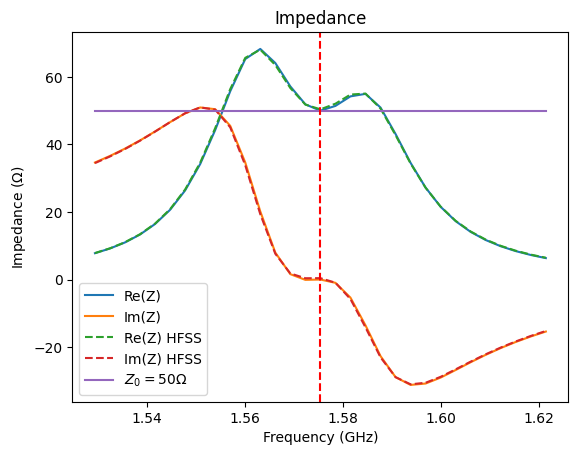

In [8]:
dprobe, Yp, tg01, tg10, deltaL, deltaW = estimIt
ZinP = Z_par_g(dprobe, Yp, tg01, tg10, deltaL, deltaW, param[0], param[1], param[2], param[3], sweep, geom)

plt.figure()
plt.plot(freqs / 1e9, np.real(ZinP), label='Re(Z)')
plt.plot(freqs / 1e9, np.imag(ZinP), label='Im(Z)')
plt.plot(freqs / 1e9, real_z, label='Re(Z) HFSS', linestyle='--')
plt.plot(freqs / 1e9, imag_z, label='Im(Z) HFSS', linestyle='--')
plt.plot(freqs / 1e9, [Z0] * len(freqs), label=r'$Z_0=50\Omega$')
plt.axvline(x=center_freq / 1e9, color='r', linestyle='--')
plt.xlabel('Frequency (GHz)')
plt.ylabel('Impedance (' + r'$\Omega$' + ')')
plt.title('Impedance')
plt.legend()
plt.savefig(results_folder+'/impedance_comparison_final.png', format='png', dpi=300)


3D
PyAEDT INFO: Parsing /tmp/tmp_1k443ou.ansys/Planar_Array.aedt.
PyAEDT INFO: File /tmp/tmp_1k443ou.ansys/Planar_Array.aedt correctly loaded. Elapsed time: 0m 0sec
PyAEDT INFO: aedt file load time 0.22871708869934082


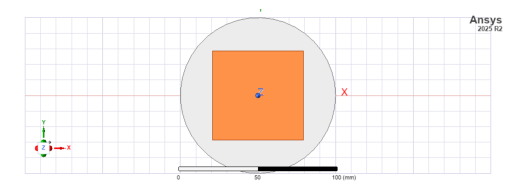

In [9]:
Rad_3D = hfss.field_setups[0]
print(Rad_3D.name)
Rad_3D.theta_step = "1deg"
Rad_3D.phi_step = "1deg"
Rad_3D.theta_start = "-180deg"

# Boresight of the planar patch is +Z (Theta=0). Any Phi value works exactly
# at the pole, so Phi=0 is used by convention (the spherical version fixed
# Theta=90, Phi=90 because its boresight was along +Y).
variations = hfss.get_nominal_variation()
variations["Freq"] = ["All"]
variations["Theta"] = ["0deg"]
variations["Phi"] = ["0deg"]
axialratio_ffd_plot = hfss.post.create_report(expressions="dB(AxialRatioValue)",
                                               setup_sweep_name="Sweep_Discrete",
                                               variations=variations,
                                               primary_sweep_variable="Freq",
                                               context="3D",
                                               report_category="Far Fields",
                                               plot_type="Rectangular Plot",
                                               plot_name="Axial Ratio (dB)"
                                               )
hfss.post.export_report_to_csv(project_dir=results_folder, plot_name="Axial Ratio (dB)")

variations = hfss.get_nominal_variation()
variations["Freq"] = ["All"]
variations["Theta"] = ["0deg"]
variations["Phi"] = ["0deg"]
axialratio_ffd_plot = hfss.post.create_report(expressions=["dB(GainLHCP)", "dB(GainRHCP)"],
                                               setup_sweep_name="Sweep_Discrete",
                                               variations=variations,
                                               primary_sweep_variable="Freq",
                                               context="3D",
                                               report_category="Far Fields",
                                               plot_type="Rectangular Plot",
                                               plot_name="Gain (dB)"
                                               )
hfss.post.export_report_to_csv(project_dir=results_folder, plot_name="Gain (dB)")

selections = ["Dielectric"]
for i in range(len(Xs)):
    selections.append("Patch"+str(i+1))

hfss.post.export_model_picture(full_name=results_folder.replace('/', '\\')+"\\Array_View.png", show_axis=True,
                                show_grid=True, show_ruler=True, show_region='Default', selections=selections,
                                field_selections="all", orientation='top', width=0, height=0)

img = mpimg.imread(results_folder+"/Array_View.png")
plt.imshow(img)
plt.axis("off")
plt.show()


PyAEDT INFO: Parsing design objects. This operation can take time
PyAEDT INFO: Refreshing bodies from Object Info
PyAEDT INFO: Bodies Info Refreshed Elapsed time: 0m 0sec
PyAEDT INFO: 3D Modeler objects parsed. Elapsed time: 0m 0sec
PyAEDT INFO: Active Design set to Planar


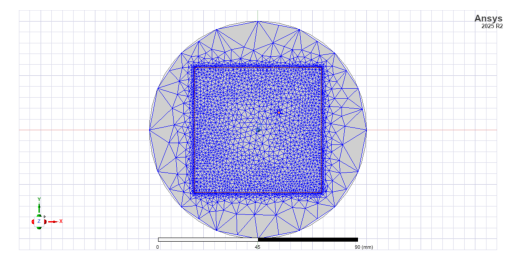

In [10]:
mesh_plot = hfss.post.create_fieldplot_volume(["Dielectric"], quantity="Mesh", field_type="Fields",
                                               setup="Resonance_Band : LastAdaptive", plot_name="Diel_Mesh")

hfss.post.export_model_picture(full_name=results_folder.replace('/', '\\')+"\\Back_View.png", show_axis=True,
                                show_grid=True, show_ruler=True, show_region='Default',
                                selections=["Dielectric", "Patch1"], field_selections="all", orientation='top',
                                width=0, height=0)

img = mpimg.imread(results_folder+"/Back_View.png")
plt.imshow(img)
plt.axis("off")
plt.show()


In [11]:
hfss.post.update_report_dynamically = True

# For a planar patch, boresight is Theta=0, so a great circle THROUGH
# boresight is a THETA sweep at FIXED Phi (not a Phi sweep at fixed Theta,
# as in the spherical version, which would only trace a cut through
# boresight there because the patch sat at Theta=90). Two such cuts give the
# two principal planes: Phi=0 (E-plane-like) and Phi=90 (H-plane-like).
variations = hfss.get_nominal_variation()
variations["Freq"] = [str(center_freq/1e9)+"GHz"]
variations["Theta"] = ["All"]
variations["Phi"] = ["0deg"]
axialratio_ffd_plot = hfss.post.create_report(expressions="dB(AxialRatioValue)",
                                               setup_sweep_name="Sweep_Discrete",
                                               variations=variations,
                                               primary_sweep_variable="Theta",
                                               context="3D",
                                               report_category="Far Fields",
                                               plot_type="Rectangular Plot",
                                               plot_name="Axial Ratio Phi0 (dB)"
                                               )
hfss.post.export_report_to_csv(project_dir=results_folder, plot_name="Axial Ratio Phi0 (dB)")

variations = hfss.get_nominal_variation()
variations["Freq"] = [str(center_freq/1e9)+"GHz"]
variations["Theta"] = ["All"]
variations["Phi"] = ["90deg"]
axialratio_ffd_plot = hfss.post.create_report(expressions="dB(AxialRatioValue)",
                                               setup_sweep_name="Sweep_Discrete",
                                               variations=variations,
                                               primary_sweep_variable="Theta",
                                               context="3D",
                                               report_category="Far Fields",
                                               plot_type="Rectangular Plot",
                                               plot_name="Axial Ratio Phi90 (dB)"
                                               )
hfss.post.export_report_to_csv(project_dir=results_folder, plot_name="Axial Ratio Phi90 (dB)")

variations = hfss.get_nominal_variation()
variations["Freq"] = [str(center_freq/1e9)+"GHz"]
variations["Theta"] = ["All"]
variations["Phi"] = ["All"]
gain_ffd_plot = hfss.post.create_report(expressions=["dB(GainLHCP)", "dB(GainRHCP)"],
                                         setup_sweep_name="Sweep_Discrete",
                                         variations=variations,
                                         context="3D",
                                         report_category="Far Fields",
                                         plot_type="3D Polar Plot",
                                         plot_name="Gain 3D (dB)"
                                         )
hfss.post.export_report_to_csv(project_dir=results_folder, plot_name="Gain 3D (dB)")

variations = hfss.get_nominal_variation()
variations["Freq"] = [str(center_freq/1e9)+"GHz"]
variations["Theta"] = ["All"]
variations["Phi"] = ["0deg"]
gain_ffd_plot = hfss.post.create_report(expressions=["dB(GainLHCP)", "dB(GainRHCP)"],
                                         setup_sweep_name="Sweep_Discrete",
                                         variations=variations,
                                         primary_sweep_variable="Theta",
                                         context="3D",
                                         report_category="Far Fields",
                                         plot_type="Radiation Pattern",
                                         plot_name="Gain Phi0 (dB)"
                                         )
hfss.post.export_report_to_csv(project_dir=results_folder, plot_name="Gain Phi0 (dB)")

variations = hfss.get_nominal_variation()
variations["Freq"] = [str(center_freq/1e9)+"GHz"]
variations["Theta"] = ["All"]
variations["Phi"] = ["90deg"]
gain_ffd_plot = hfss.post.create_report(expressions=["dB(GainLHCP)", "dB(GainRHCP)"],
                                         setup_sweep_name="Sweep_Discrete",
                                         variations=variations,
                                         primary_sweep_variable="Theta",
                                         context="3D",
                                         report_category="Far Fields",
                                         plot_type="Radiation Pattern",
                                         plot_name="Gain Phi90 (dB)"
                                         )
hfss.post.export_report_to_csv(project_dir=results_folder, plot_name="Gain Phi90 (dB)")

reportS = hfss.post.create_report(expressions=["dB(S(Wave_Port1,Wave_Port1))"], setup_sweep_name="Sweep_Discrete",
                                   plot_name="S_11", variations=hfss.get_nominal_variation())
hfss.post.export_report_to_csv(project_dir=results_folder, plot_name="S_11")


PyAEDT WARNING: No report category provided. Automatically identified Modal Solution Data


'/home/lap1/Documentos/Alunos/JoaoPedroFalcao/planar_diagonal_feed/Results/case_er=2.55_h=1.524mm_f=1575MHz/S_11.csv'

In [12]:
variations = hfss.available_variations.nominal_values
variations["Freq"] = [str(center_freq/1e9)+"GHz"]
variations["Theta"] = ["All"]
variations["Phi"] = ["All"]
gain_ffd_plot = hfss.post.create_report(expressions=["re(rEPhi)"],
                                         setup_sweep_name="Sweep_Discrete",
                                         variations=variations,
                                         context="3D",
                                         report_category="Far Fields",
                                         plot_type="3D Polar Plot",
                                         plot_name="rE_Phi_re"
                                         )
hfss.post.export_report_to_csv(project_dir=results_folder, plot_name="rE_Phi_re")

gain_ffd_plot = hfss.post.create_report(expressions=["im(rEPhi)"],
                                         setup_sweep_name="Sweep_Discrete",
                                         variations=variations,
                                         context="3D",
                                         report_category="Far Fields",
                                         plot_type="3D Polar Plot",
                                         plot_name="rE_Phi_im"
                                         )
hfss.post.export_report_to_csv(project_dir=results_folder, plot_name="rE_Phi_im")

gain_ffd_plot = hfss.post.create_report(expressions=["re(rETheta)"],
                                         setup_sweep_name="Sweep_Discrete",
                                         variations=variations,
                                         context="3D",
                                         report_category="Far Fields",
                                         plot_type="3D Polar Plot",
                                         plot_name="rE_Theta_re"
                                         )
hfss.post.export_report_to_csv(project_dir=results_folder, plot_name="rE_Theta_re")

gain_ffd_plot = hfss.post.create_report(expressions=["im(rETheta)"],
                                         setup_sweep_name="Sweep_Discrete",
                                         variations=variations,
                                         context="3D",
                                         report_category="Far Fields",
                                         plot_type="3D Polar Plot",
                                         plot_name="rE_Theta_im"
                                         )
hfss.post.export_report_to_csv(project_dir=results_folder, plot_name="rE_Theta_im")


'/home/lap1/Documentos/Alunos/JoaoPedroFalcao/planar_diagonal_feed/Results/case_er=2.55_h=1.524mm_f=1575MHz/rE_Theta_im.csv'

In [13]:
reportEff3 = hfss.post.reports_by_category.antenna_parameters("RadiationEfficiency",
                                                               setup="Resonance_Band : Sweep_Discrete",
                                                               infinite_sphere="3D")
reportEff3.report_type = "Data Table"
reportEff3.create()
reportEff3.plot_name = "Efficiency"
reportEff3.variations = hfss.get_nominal_variation()
data = reportEff3.get_solution_data()
data.export_data_to_csv(os.path.join(results_folder, "Efficiency_Data.csv"))


PyAEDT INFO: Solution Data Correctly Loaded.
Time to initialize solution data:0.0023272037506103516
Time to initialize solution data:0.0037648677825927734


True

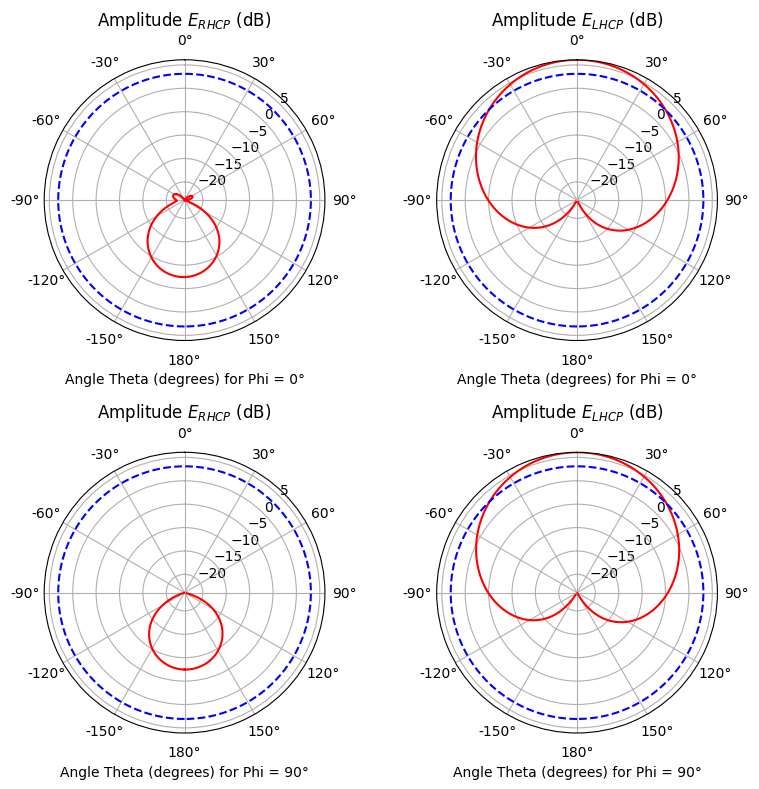

In [14]:
with open(results_folder+"/history.txt", "a", encoding="utf-8") as f:
    f.write("\n3dB Beamwidth Results:\n")

    def calc_3db_angle(gg, angulos, label):
        N = len(gg)
        p = np.argmax(gg)
        t = gg[p] - 3

        r = p
        while gg[(r+1) % N] > t:
            r = (r+1) % N
        ar = angulos[(r+1) % N]

        l = p
        while gg[(l-1) % N] > t:
            l = (l-1) % N
        al = angulos[(l-1) % N]

        bw = (ar - al) % 360
        f.write("\n3dB Beamwidth " + label + ": " + str(bw) + " degrees")

    # RHCP and LHCP. Both cuts sweep Theta from -180 to 180 deg, at fixed
    # Phi=0 (E-plane-like cut) and Phi=90 (H-plane-like cut) -- the boresight
    # direction (Theta=0) sits at the middle of each of these arrays.
    angulos = np.arange(-180, 181, 1)
    angles = np.arange(0, 360, 30)
    angles_labels = ['0°', '30°', '60°', '90°', '120°', '150°', '180°', '-150°', '-120°', '-90°', '-60°', '-30°']
    dtr = np.pi/180

    df_RHCP_ph0 = pd.read_csv(results_folder + '/Gain Phi0 (dB).csv')
    df_LHCP_ph0 = pd.read_csv(results_folder + '/Gain Phi0 (dB).csv')

    Erhcp = df_RHCP_ph0["dB(GainRHCP) []"].to_numpy(dtype=float)
    Elhcp = df_LHCP_ph0["dB(GainLHCP) []"].to_numpy(dtype=float)

    gain = np.max([np.max(Erhcp), np.max(Elhcp)])

    fig, axs2 = plt.subplots(2, 2, figsize=(8, 8), subplot_kw={'projection': 'polar'})

    gg = Erhcp
    axs2[0, 0].plot(angulos * dtr, gg, color='red')
    axs2[0, 0].plot(angulos * dtr, [gain-3]*len(angulos), color='b', linestyle='--')
    axs2[0, 0].set_title('Amplitude '+r'$E_{RHCP}$'+' (dB)')
    axs2[0, 0].set_xlabel('Angle Theta (degrees) for Phi = 0°')
    axs2[0, 0].set_theta_zero_location('N')
    axs2[0, 0].set_theta_direction(-1)
    axs2[0, 0].set_rlim(gain-30, gain)
    axs2[0, 0].set_thetagrids(angles, labels=angles_labels)
    axs2[0, 0].set_rlabel_position(45)

    calc_3db_angle(gg, angulos, 'RHCP Phi=0°')

    gg = Elhcp
    axs2[0, 1].plot(angulos * dtr, gg, color='red')
    axs2[0, 1].plot(angulos * dtr, [gain-3]*len(angulos), color='b', linestyle='--')
    axs2[0, 1].set_title('Amplitude '+r'$E_{LHCP}$'+' (dB)')
    axs2[0, 1].set_xlabel('Angle Theta (degrees) for Phi = 0°')
    axs2[0, 1].set_theta_zero_location('N')
    axs2[0, 1].set_theta_direction(-1)
    axs2[0, 1].set_rlim(gain-30, gain)
    axs2[0, 1].set_thetagrids(angles, labels=angles_labels)
    axs2[0, 1].set_rlabel_position(45)

    calc_3db_angle(gg, angulos, 'LHCP Phi=0°')

    df_RHCP_ph90 = pd.read_csv(results_folder + '/Gain Phi90 (dB).csv')
    df_LHCP_ph90 = pd.read_csv(results_folder + '/Gain Phi90 (dB).csv')

    Erhcp_full = df_RHCP_ph90["dB(GainRHCP) []"].to_numpy(dtype=float)
    Elhcp_full = df_LHCP_ph90["dB(GainLHCP) []"].to_numpy(dtype=float)

    gg = Erhcp_full
    axs2[1, 0].plot(angulos * dtr, gg, color='red')
    axs2[1, 0].plot(angulos * dtr, [gain-3]*len(angulos), color='b', linestyle='--')
    axs2[1, 0].set_title('Amplitude '+r'$E_{RHCP}$'+' (dB)')
    axs2[1, 0].set_xlabel('Angle Theta (degrees) for Phi = 90°')
    axs2[1, 0].set_theta_zero_location('N')
    axs2[1, 0].set_theta_direction(-1)
    axs2[1, 0].set_rlim(gain-30, gain)
    axs2[1, 0].set_thetagrids(angles, labels=angles_labels)
    axs2[1, 0].set_rlabel_position(45)

    calc_3db_angle(gg, angulos, 'RHCP Phi=90°')

    gg = Elhcp_full
    axs2[1, 1].plot(angulos * dtr, gg, color='red')
    axs2[1, 1].plot(angulos * dtr, [gain-3]*len(angulos), color='b', linestyle='--')
    axs2[1, 1].set_title('Amplitude '+r'$E_{LHCP}$'+' (dB)')
    axs2[1, 1].set_xlabel('Angle Theta (degrees) for Phi = 90°')
    axs2[1, 1].set_theta_zero_location('N')
    axs2[1, 1].set_theta_direction(-1)
    axs2[1, 1].set_rlim(gain-30, gain)
    axs2[1, 1].set_thetagrids(angles, labels=angles_labels)
    axs2[1, 1].set_rlabel_position(45)

    calc_3db_angle(gg, angulos, 'LHCP Phi=90°')

    plt.tight_layout()
    plt.savefig(results_folder+'/RHCP_LHCP_Patterns.png', format='png', dpi=300)

    end = time.time()
    f.write("\nSimulation Finished at: " + datetime.now().strftime('%d/%m/%Y %H:%M:%S') + "\n")
    f.write("------------------------------------------------------")


### Workbench
Use this section for ad-hoc checks (design variations, extra plots, quick geometry edits) while iterating on the design.

In [16]:
hfss.save_project()
hfss.release_desktop()
temp_folder.cleanup()

AttributeError: 'Hfss' object has no attribute '_oproject'